# ClaimGuard AI — Week 3: Explainability & Anomaly Detection

Two independent signals on top of the Week 2 XGBoost risk model:

1. **SHAP** — explains *why the model* gave a specific claim its score. This explains the
   model's reasoning, not a cause of fraud.
2. **Isolation Forest** — an unsupervised outlier score, fit without using `FraudFound_P` at
   all. It answers "how unusual is this claim's feature combination," a different question
   from "how risky does the supervised model think this claim is." The two are kept and
   shown as separate signals throughout, never merged into one number.

## 1. Reload data, split (same random_state as Week 2), and the saved model

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from src.data.load import load_raw
from src.models.train import split_data, xy, RANDOM_STATE
from src.explainability.shap_utils import compute_shap_values, global_importance, explain_instance
from src.anomaly.isolation_forest import build_isolation_forest_pipeline, anomaly_scores

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

df = load_raw('../data/raw/fraud_oracle.csv')
train_df, val_df, test_df = split_data(df)  # identical split as Week 2 (same random_state)
X_train, y_train = xy(train_df)
X_test, y_test = xy(test_df)

selected_pipeline = joblib.load('../models/selected_pipeline_xgboost.joblib')
test_prob = selected_pipeline.predict_proba(X_test)[:, 1]
print('Loaded model, scored', len(X_test), 'test claims')


/Users/apple/Downloads/My Files/My File/Projects/ClaimGaurdAI/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded model, scored 3084 test claims


## 2. Global feature importance (SHAP)

Computed on the held-out test set so importance reflects out-of-sample behavior.

In [2]:
shap_values, dense_test, feature_names = compute_shap_values(selected_pipeline, X_test)
print('SHAP values shape:', shap_values.shape, '| features:', len(feature_names))

global_imp = global_importance(shap_values, feature_names, top_n=15)
global_imp


SHAP values shape: (3084, 143) | features: 143


,feature,mean_abs_shap
0,Make_VW,1.738908
1,AddressChange_Claim_under 6 months,0.913515
2,Make_Dodge,0.706776
3,PolicyType_Sport - All Perils,0.561816
4,AgeOfVehicle_2 years,0.497070
5,Make_Nisson,0.486997
6,AddressChange_Claim_2 to 3 years,0.385061
7,Age,0.361969
8,PolicyType_Utility - Collision,0.350137
9,Sex_Female,0.339556


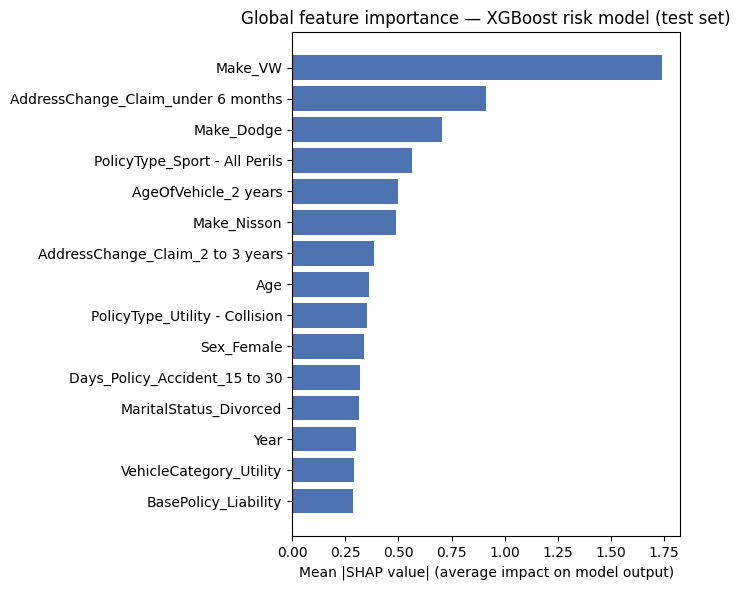

In [3]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(global_imp['feature'][::-1], global_imp['mean_abs_shap'][::-1], color='#4C72B0')
ax.set_xlabel('Mean |SHAP value| (average impact on model output)')
ax.set_title('Global feature importance — XGBoost risk model (test set)')
plt.tight_layout()
plt.savefig('../reports/figures/shap_global_importance.png', dpi=150)
plt.show()


**Reading this chart:** these are the features the model relies on most when ranking claims — a description of the *model's* behavior on this historical, dataset-defined label. It is not a validated list of real-world fraud indicators, and must not be read as such outside this project's documented scope.

## 3. Per-claim explanation (local SHAP)

One illustrative high-scored claim and one low-scored claim from the test set.

In [4]:
high_idx = int(np.argmax(test_prob))
low_idx = int(np.argmin(test_prob))

for label, idx in [('Highest-scored test claim', high_idx), ('Lowest-scored test claim', low_idx)]:
    print(f'--- {label} (row {idx}, model score={test_prob[idx]:.3f}) ---')
    local = explain_instance(shap_values[idx], feature_names, dense_test[idx], top_n=6)
    print(local.to_string(index=False))
    print()


--- Highest-scored test claim (row 1676, model score=0.986) ---
                           feature  feature_value  shap_value
                           Make_VW            0.0   -1.749757
AddressChange_Claim_under 6 months            0.0    0.908972
                        Make_Dodge            0.0   -0.706785
     PolicyType_Sport - All Perils            0.0   -0.543340
                       Make_Nisson            0.0   -0.484037
              AgeOfVehicle_2 years            0.0   -0.472039

--- Lowest-scored test claim (row 2147, model score=0.000) ---
                           feature  feature_value  shap_value
                           Make_VW            0.0   -1.720282
AddressChange_Claim_under 6 months            0.0    0.896930
                               Age           21.0   -0.735578
                        Make_Dodge            1.0   -0.687372
     PolicyType_Sport - All Perils            0.0   -0.546599
                       Make_Nisson            0.0   -0.488566



## 4. Isolation Forest — independent anomaly signal

Fit on the TRAINING fold only, using no target label at all (unsupervised). `contamination=0.06` is a reporting convenience near the dataset's own flag rate — it does not imply outliers are fraud.

In [5]:
iso_pipeline = build_isolation_forest_pipeline(contamination=0.06)
iso_pipeline.fit(X_train)  # unsupervised: y is never used

test_anomaly_score, test_is_anomaly = anomaly_scores(iso_pipeline, X_test)
print('Flagged as statistical outliers:', test_is_anomaly.sum(), 'of', len(X_test), f'({test_is_anomaly.mean():.1%})')


Flagged as statistical outliers: 175 of 3084 (5.7%)


## 5. Model risk score vs. anomaly score — two distinct signals

If these two signals were the same thing, points would fall on a clean diagonal. They should not.

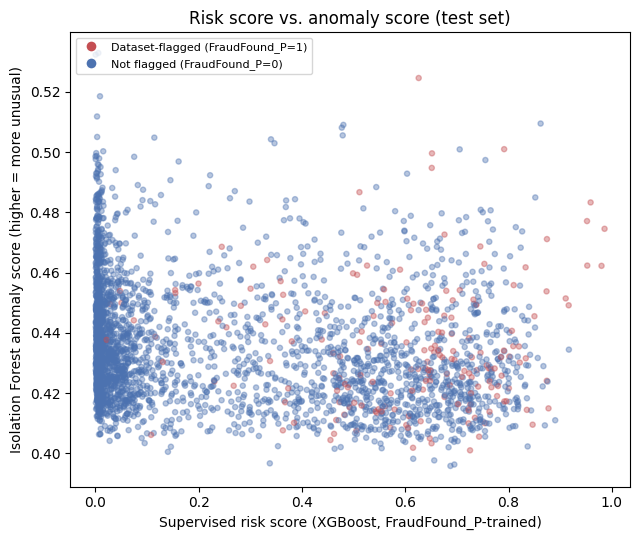

Pearson correlation between risk score and anomaly score: -0.178


In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
colors = np.where(y_test == 1, '#C44E52', '#4C72B0')
ax.scatter(test_prob, test_anomaly_score, c=colors, alpha=0.4, s=14)
ax.set_xlabel('Supervised risk score (XGBoost, FraudFound_P-trained)')
ax.set_ylabel('Isolation Forest anomaly score (higher = more unusual)')
ax.set_title('Risk score vs. anomaly score (test set)')

from matplotlib.lines import Line2D
legend_elems = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#C44E52', markersize=8, label='Dataset-flagged (FraudFound_P=1)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#4C72B0', markersize=8, label='Not flagged (FraudFound_P=0)'),
]
ax.legend(handles=legend_elems, loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('../reports/figures/risk_vs_anomaly_scatter.png', dpi=150)
plt.show()

corr = np.corrcoef(test_prob, test_anomaly_score)[0, 1]
print('Pearson correlation between risk score and anomaly score:', round(corr, 3))


## 6. Save scored test set (risk score + anomaly score + SHAP top reasons) for the dashboard

In [7]:
top_reason_strs = []
for i in range(len(X_test)):
    row = explain_instance(shap_values[i], feature_names, dense_test[i], top_n=3)
    reasons = '; '.join(f"{r.feature}={r.shap_value:+.2f}" for r in row.itertuples())
    top_reason_strs.append(reasons)

scored_test = test_df.reset_index(drop=True).copy()
scored_test['risk_score'] = test_prob
scored_test['anomaly_score'] = test_anomaly_score
scored_test['is_statistical_outlier'] = test_is_anomaly
scored_test['top_shap_reasons'] = top_reason_strs

out_path = '../data/processed/scored_test_claims.csv'
scored_test.to_csv(out_path, index=False)
print('Saved', len(scored_test), 'scored claims to', out_path)
scored_test[['FraudFound_P', 'risk_score', 'anomaly_score', 'is_statistical_outlier', 'top_shap_reasons']].head()


Saved 3084 scored claims to ../data/processed/scored_test_claims.csv


,FraudFound_P,risk_score,anomaly_score,is_statistical_outlier,top_shap_reasons
0,0,0.023787,0.407565,False,Make_VW=-1.75; AddressChange_Claim_under 6 mon...
1,0,0.211278,0.444446,False,Make_VW=-1.75; AddressChange_Claim_under 6 mon...
2,0,0.003357,0.485675,True,Make_VW=-1.72; AddressChange_Claim_under 6 mon...
3,0,0.690703,0.407810,False,Make_VW=-1.75; AddressChange_Claim_under 6 mon...
4,0,0.121872,0.428549,False,Make_VW=-1.74; AddressChange_Claim_under 6 mon...


In [8]:
import joblib
joblib.dump(iso_pipeline, '../models/isolation_forest_pipeline.joblib')
print('Saved Isolation Forest pipeline')


Saved Isolation Forest pipeline


## 7. Summary

- Global SHAP importance (Section 2) and a per-claim breakdown (Section 3) are available for every scored claim — these will power the dashboard's claim-detail view.
- The Isolation Forest anomaly score (Section 4) is a genuinely separate signal from the supervised risk score, fit without ever using `FraudFound_P` — the scatter plot and correlation in Section 5 confirm they are not redundant.
- `data/processed/scored_test_claims.csv` carries both scores plus top SHAP reasons per claim, ready for the Week 3 Streamlit dashboard.
- As always: neither score is evidence of fraud. Both require human review, and this remains a historical (1994–1996), dataset-defined-label demonstration.